# Aula 13: **Da classe `Musica` à plataforma musical**

**Programação orientada a objetos | Continuação da Aula 12**

Nesta aula, a classe `Musica` desenvolvida anteriormente (aulas 11 e 12) será organizada em um módulo Python. 

Em seguida, será criaremos uma nova a classe, chamada `Catalogo` para administrar uma coleção de músicas, com cadastro, prevenção de duplicidades, consultas, remoção, reprodução e favoritos.

A implementação será feita progressivamente em arquivos `.py`, enquanto este notebook reunirá as explicações, os slides e os testes. 

---
---

### Organização do projeto e ambiente de execução

Crie uma pasta chamada `Plataforma_Musical` e abra-a no VS Code. O projeto terá a seguinte estrutura:

```text
Plataforma_Musical/
├── musica.py       # Classe que representa uma música
├── catalogo.py     # Classe que administra a coleção 
└── main.ipynb      # Explicações e testes da aula
```

No início, somente `musica.py` e o notebook precisam existir. 


---
---

### Atualização automática dos módulos

Como vamos trabalhar com arquivos `.py` e um jupyter Notebbook, utitlizaremos dos comandos para facilitar a atualização do código.
- `%load_ext autoreload`: carrega a extensão `autoreload` do IPython, resposável por permitir a atualização automática dos módulos Python.

- `%autoreload 2`: Ativa a atualização automática dos módulos importados antes da excução de cada célula, permitindo reconhecer alterações 


In [2]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


**slide 1**

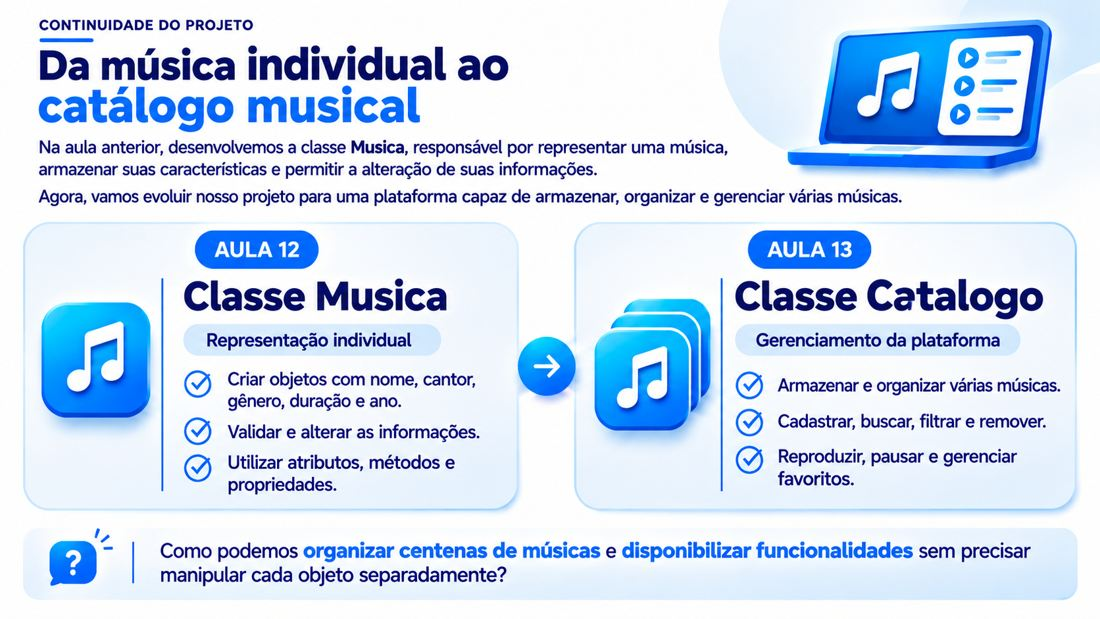

## Passo 1: Transformando a classe `Musica` em módulo

Na Aula 12, a classe `Musica` foi construída dentro de um único notebook. 

- O primeiro passo é transferir **a versão final daquela aula, para um arquivo chamado `musica.py`.

---

**O que é o módulo?** 

Um **módulo** é um arquivo Python que reúne definições reutilizáveis, como classes e funções. Ao separar a classe dos testes, organizamos o projeto sem alterar inicialmente o comportamento do programa.


**slide 2**

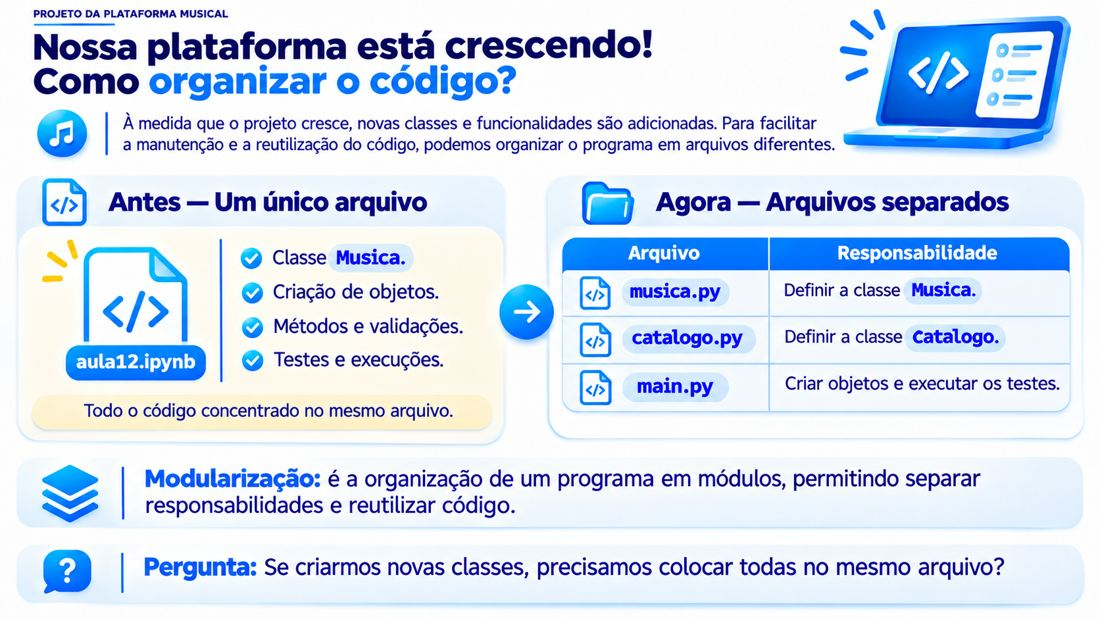

### Implementação inicial em `musica.py`

Crie um arquivo `musica.py` na pasta do projeto e insira o código da classe `Musica` feito na Aula 12 sem alterar nada. 



---
**Classe `Musica` — versão da Aula 12**

O trecho a seguir precisa ser copiado ao arquivo **`musica.py`**. Após salvá-lo, os objetos serão criados e testados no notebook.

```python
class Musica:
    def __init__(self, nome, cantor, genero, duracao, ano): 

        #=========================================================================================#
        # Validação
        if not isinstance(nome, str) or not nome.strip():
             raise ValueError("O nome da música deve ser um texto não vazio!")
        if not isinstance(cantor, str) or not cantor.strip():
                     raise ValueError("Cantor(a) da música deve ser um texto não vazio!")
        if not isinstance(genero, str) or not genero.strip():
                             raise ValueError("Gênero da música deve ser um texto não vazio!")
        if type(duracao) is not int or duracao <=0:
             raise ValueError("O atributo duração deve ser um número inteiro positivo.")
        if type(ano) is not int or ano <=0:
                     raise ValueError("O atributo ano deve ser um número inteiro positivo.")
        #=========================================================================================#

        self._nome = nome.strip()
        self._cantor = cantor.strip()
        self._genero = genero.strip()
        self._duracao = duracao
        self._ano = ano
        
        # Atributos de controle
        self.reproducoes = 0 # int, conta as reproduções iniciadas.
        self.tocando = False # bool, indica se a música está tocando.
        self.favorito = False
    #=========================================================================================#
    
    #=========================================================================================#
    # Propriedades de leitura (@property)
    @property
    def nome(self):
        return self._nome

    @property
    def cantor(self):
        return self._cantor

    @property
    def genero(self):
        return self._genero

    @property
    def duracao(self):
        return self._duracao
    
    @property
    def ano(self):
        return self._ano
    #=========================================================================================#
    
    #=========================================================================================#
    # Representação textual do objeto (__str__)
    def __str__(self):
        minutos = self.duracao // 60
        segundos = self.duracao % 60
        return (f"{self._nome} - {self._cantor} ({self._genero}) - {minutos:02d}:{segundos:02d}")
    #=========================================================================================#
    
    #=========================================================================================#
    # Métodos de exibição de atributos   
    def mostrar_nome(self):
        print(f"Nome da música: {self._nome}.")    
        
    def mostrar_cantor(self):
        print(f"Cantor(a): {self._cantor}.")
        
    def mostrar_genero(self):
        print(f"Gênero musical: {self._genero}.")
    
    def mostrar_duracao(self):
        print(f"Duração: {self._duracao} segundos.")
    
    def mostrar_ano(self):
        print(f"Ano de lançamento: {self._ano}.")
        
    # Método para mostrar todas as informações
    def mostrar_detalhe(self):
        self.mostrar_nome()
        self.mostrar_cantor()
        self.mostrar_genero()
        self.mostrar_duracao()
        self.mostrar_ano()
        print(f"Favorito: {'Sim' if self.favorito else 'Não'}")
        print(f"Tocando: {'Sim' if self.tocando else 'Não'}")
        print(f"Reproduções: {self.reproducoes}")
    #=========================================================================================#  
       
    #=========================================================================================# 
    def reproduzir(self):

        # Verifica se a música NÃO está tocando.
        if self.tocando == False:
            self.tocando = True # modifica o atributo.
            self.reproducoes += 1 # incrementa o contador de reproduções.
            print(f"Reproduzindo a música: {self._nome}.")

        else:
            print(f"A música {self._nome} já está sendo reproduzida.") # Se já estiver tocando, não inicia outra reprodução.
    
    
    # Método que pausa a reprodução da música.        
    def pausar(self):
         # Verifica se a música está tocando.
        if self.tocando == True:
            self.tocando = False
            print(f"A reprodução da música {self._nome} foi pausada.")

        else:
            print("Nenhuma música está sendo reproduzida.") # Não altera o estado se a música já estiver parada.


    def favoritar(self):
        if self.favorito == False:
            self.favorito = True
            print(f"A música : {self._nome} foi adicionada aos favoritos!")
        else:
            print(f"A música : {self._nome} já está nos favoritos!")

    def defavoritar(self):
            if self.favorito == True:
                self.favorito = False
                print(f"A música : {self._nome} foi removida dos favoritos!")
            else:
                print(f"A música : {self._nome} não está nos favoritos!")

    #=========================================================================================#
    
    #=========================================================================================#
    # Métodos de Alterações
    
    def alterar_nome(self, novo_nome):
        if not isinstance(novo_nome, str) or not novo_nome.strip():
            raise ValueError("O nome da música deve ser um texto não vazio.")
        self._nome = novo_nome.strip()
        print(f"Nome atualizado para: {self._nome}")

    def alterar_cantor(self, novo_cantor):
        if not isinstance(novo_cantor, str) or not novo_cantor.strip():
            raise ValueError("O nome do(a) cantor(a) deve ser um texto não vazio.")
        self._cantor = novo_cantor.strip()
        print(f"Cantor(a) atualizado(a) para: {self._cantor}")  

    def alterar_genero(self, novo_genero):
        if not isinstance(novo_genero, str) or not novo_genero.strip():
            raise ValueError("O gênero musical deve ser um texto não vazio.")
        self._genero = novo_genero.strip()
        print(f"Gênero atualizado para: {self._genero}")  

    def alterar_duracao(self, nova_duracao):
        if type(nova_duracao) is not int or nova_duracao <= 0:
            raise ValueError("A duração deve ser um número inteiro positivo.")
        self._duracao = nova_duracao
        print(f"Duração atualizada para: {self._duracao} segundos.")  

    def alterar_ano(self, novo_ano):
        if type(novo_ano) is not int or novo_ano <= 0:
            raise ValueError("O ano de lançamento deve ser um número inteiro positivo.")
        self._ano = novo_ano
        print(f"Ano de lançamento atualizado para: {self._ano}") 
    #=========================================================================================#
```

**Estrutura após o Passo 1**

```text
Plataforma_Musical/
├── musica.py
└── main.ipynb
```

A definição de `class Musica` está em `musica.py`; por isso, não é necessário repeti-la no notebook. O próximo passo é importar a classe.

---
---

## Passo 2: Importando o módulo `musica.py`

O nome do arquivo é `musica.py`, mas a classe declarada nele é `Musica`. 

- Usaremos a instrução `from musica import Musica` para acessar essa classe no notebook (`main.ipynb`). Obs.: O nome do módulo (`musica`) é escrito em letras minúsculas, enquanto o nome da classe (`Musica`) segue a convenção de nomes de classes em Python.



Obs.: A importação **não cria um objeto**. Um objeto só é instanciado quando executamos `Musica(...)`, fornecendo os argumentos/atributos esperados pelo construtor `__init__`.



**slide 3**

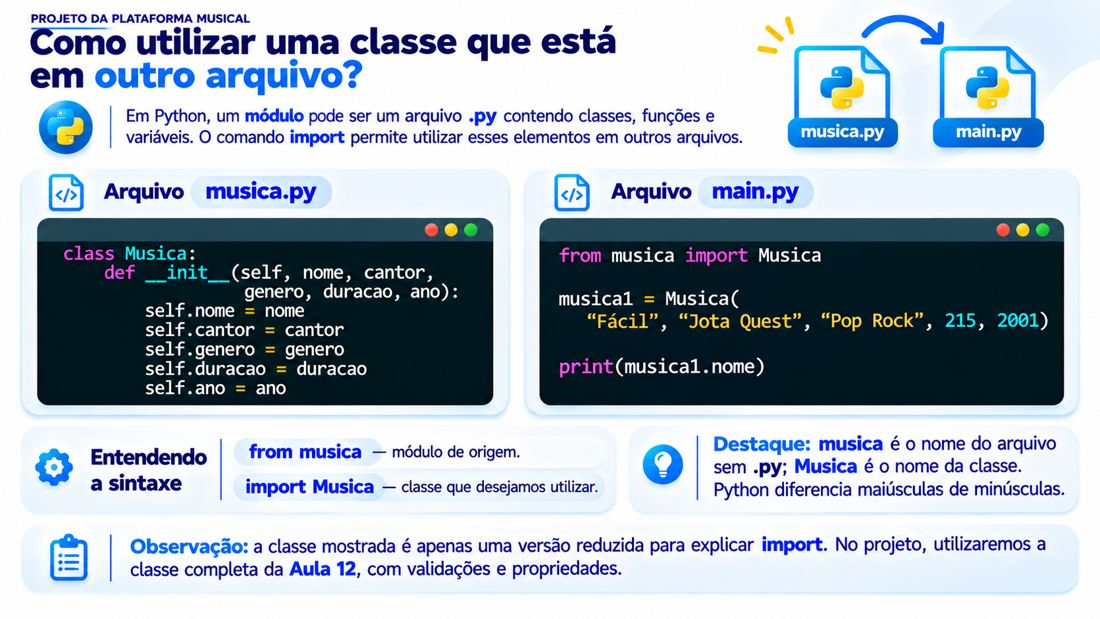


---

**Na célula abaixo:**

- importe a classe, 
- crie um objeto `m1` com os dados completo de uma musica `"nome"`, `"cantor"`, `"gênero"`, `duração` e `ano` 
- exiba-a a musica criada com `print()` 
- E por fim, chame o método `mostrar_detalhe()` para exibir todas as informações da musica.

In [ ]:
try:
    from musica import Musica
    print("Classe Musica importada com sucesso!")

except ImportError as erro:
    print(f" Erro ao importar a classe Musica: {erro}")

 Erro ao importar a classe Musica: No module named 'musicaS'


In [ ]:
m1 = Musica("Tempo Perdido", "Legião Urbana", "Rock", 302, 1986)
print(m1)

Tempo Perdido - Legião Urbana (Rock) - 05:02


In [ ]:
m1.mostrar_detalhe()

Nome da música: Tempo Perdido.
Cantor(a): Legião Urbana.
Gênero musical: Rock.
Duração: 302 segundos.
Ano de lançamento: 1986.
Favorito: Não
Tocando: Não
Reproduções: 0


In [7]:
m1.reproduzir()
m1.favoritar()
m1.mostrar_detalhe()

Reproduzindo a música: Tempo Perdido.
A música : Tempo Perdido foi adicionada aos favoritos!
Nome da música: Tempo Perdido.
Cantor(a): Legião Urbana.
Gênero musical: Rock.
Duração: 302 segundos.
Ano de lançamento: 1986.
Favorito: Sim
Tocando: Sim
Reproduções: 1


**Leitura do teste:** `m1` é uma instância de `Musica`. A chamada `Musica(...)` executa o construtor; `print(m1)` utiliza `__str__`; e `mostrar_detalhe()` executa os métodos de exibição. 


---
### Continuidade da Aula 12

> **Esta célula só funciona agora.** os métodos: `reproduzir()`, `pausar()`, `favoritar()` e `desfavoritar()` ainda existem em `Musica` porque o `musica.py` está na versão da Aula 12. Depois do Passo 4 eles saem da classe, e executar esta célula passa a gerar `AttributeError`. Esses quatro métodos foram transferida para classe `Catalogo`.


---
## Passo 3: Criando e percorrendo uma lista de músicas

Uma lista Python pode armazenar **referências a objetos**, assim como armazena números ou textos. Nesse caso, cada elemento aponta para uma instância de `Musica`, com seus próprios atributos.

- O método `append()` acrescenta um elemento ao final de uma lista (**método já visto em aula**). 
- O laço `for` percorre os objetos um a um, permitindo consultar seus atributos ou chamar seus métodos.



**slide 4**

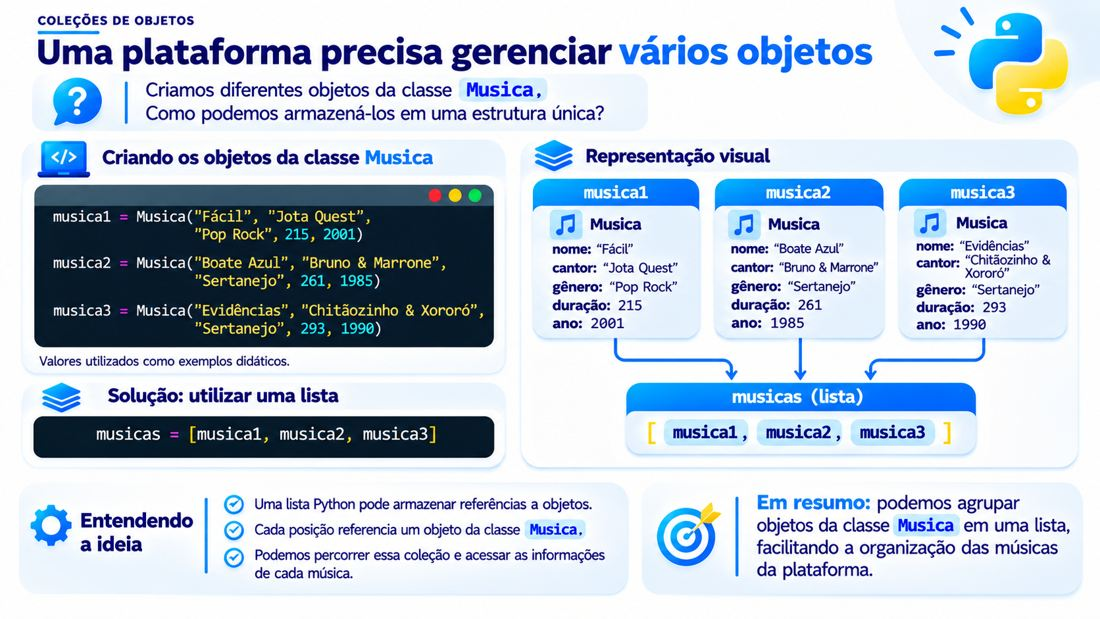

**slide 5**

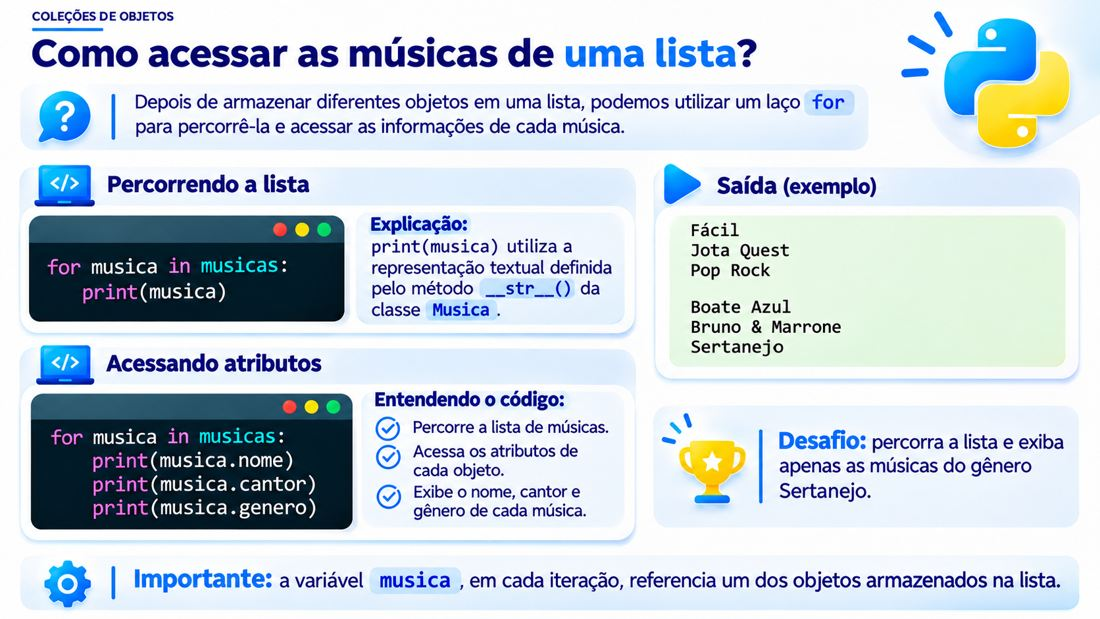

Na célula abaixo:

1. Crie três musicas da sua escolha, `m2`, `m3` e `m4`. 
2. Monte uma lista `musicas` com `m2`, `m3` e `m4`
3. Use um laço repetição para imprimir `nome da música - cantor` de cada música.

In [ ]:
m2 = Musica("Billie Jean","Michael Jackson","Pop", 294, 1982)
m3 = Musica("Vira Vira","Mamonas Assassinas","Rock", 144, 1995)
m4 = Musica("Mágico","Marina Sena","Pop", 196, 2025)

musicas = [m1, m2, m3, m4]

for musica in musicas:
    print(musica)

Tempo Perdido - Legião Urbana (Rock) - 05:02
Billie Jean - Michael Jackson (Pop) - 04:54
Vira Vira - Mamonas Assassinas (Rock) - 02:24
Mágico - Marina Sena (Pop) - 03:16


### Atividade: Seleção por gênero

Utilize um laço `for` e uma condição `if` para exibir somente as músicas cujo gênero seja `Pop`.

In [ ]:
for musica in musicas:
    if musica.genero == "Pop":
        print(musica)

Billie Jean - Michael Jackson (Pop) - 04:54
Mágico - Marina Sena (Pop) - 03:16



---
## Passo 4: Refatorando a classe `Musica`

**Refatorar** significa reorganizar o código para melhorar sua estrutura, buscando preservar o comportamento que deve continuar disponível. Neste projeto, alguns métodos passarão a ser operações da classe `Catalogo`.

A classe `Musica` ficará responsável por **dados (atributos), validações, propriedades, alterações e representação textual**. 

- Os atributos de controle: `tocando`, `favorito` e `reproducoes` e seus métodos de controle deixarão essa classe.

### Reorganização da classe Musica

Antes de modificar musica.py, crie um arquivo chamado temporario.md e copie os atributos reproducoes, tocando e favorito, juntamente com os métodos reproduzir(), pausar(), favoritar() e defavoritar().

Esses códigos serão utilizados como referência na implementação da classe Catalogo, com as adaptações necessárias.

Em seguida, remova esses atributos e métodos de Musica e atualize mostrar_detalhe() para exibir apenas as informações da música.

**slide 6**

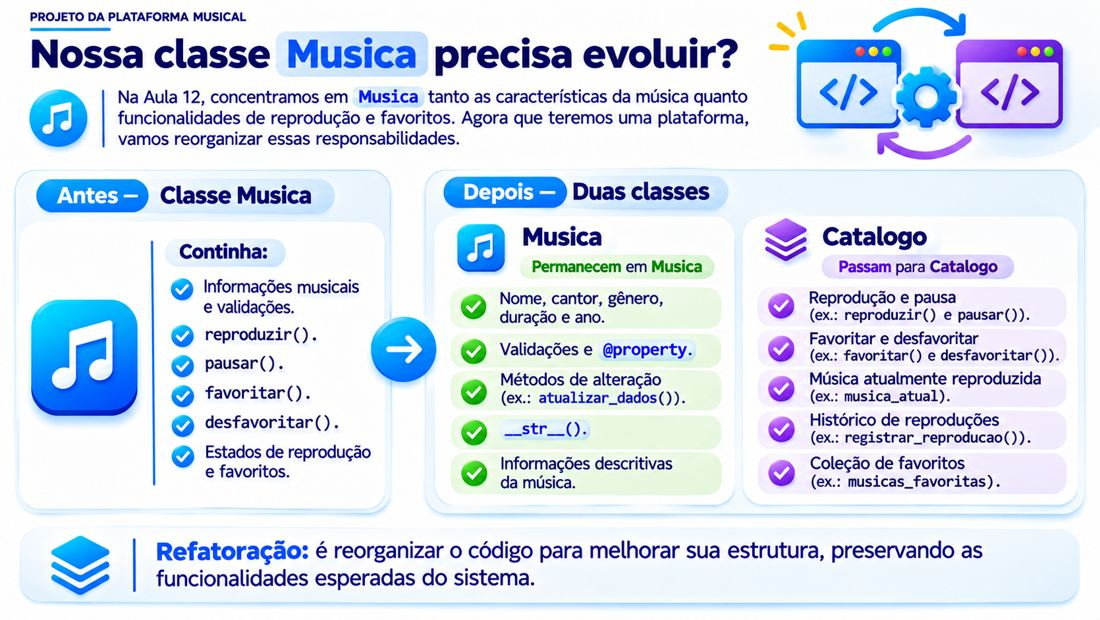

**slide 7**

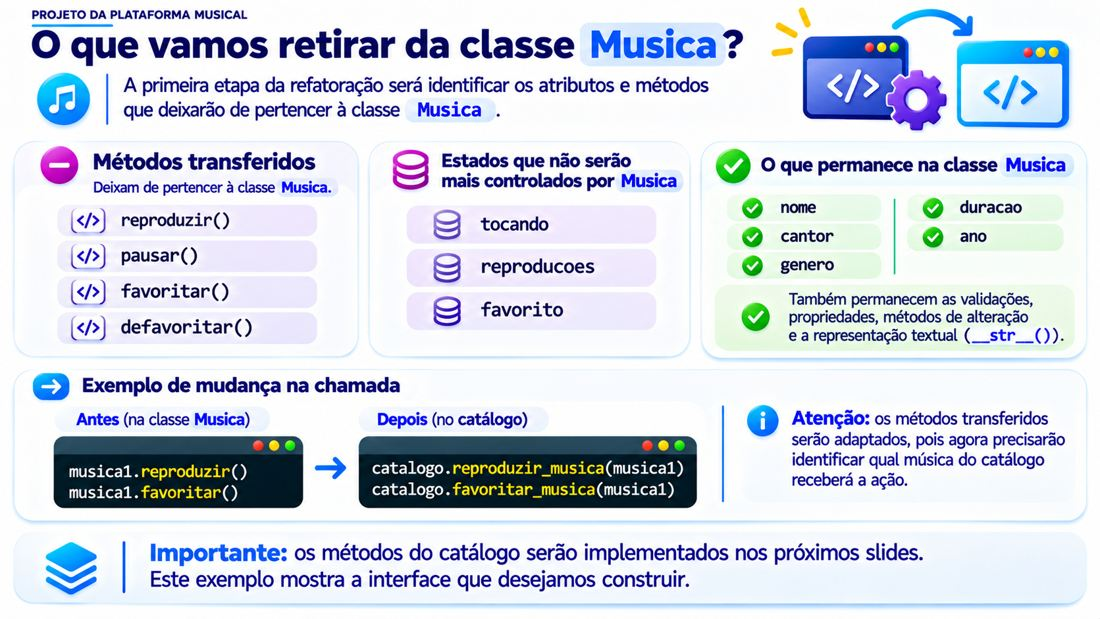

### Otimização
Para evitar a repetição de código, vamos centralizar as verificações nos métodos `_validar_texto(valor, atributo)` e `_validar_inteiro(valor, atributo)`. O parâmetro valor recebe o dado a ser validado, enquanto atributo identifica o campo na mensagem de erro. Obs.: O `_` inicial sinaliza uso interno por convenção; não constitui uma barreira de acesso privada.

Utilizaremos o decorador `@staticmethod`, que permite definir métodos dentro de uma classe sem receber automaticamente o parâmetro `self`. Isso é adequado porque as validações dependem apenas dos valores recebidos, sem precisar acessar os atributos do objeto.

Assim, podemos reutilizar os mesmos métodos na criação e na alteração das músicas, reduzindo duplicações e facilitando a manutenção do código.

Fazer três testes de validação
- um para string
- um para inteiro
- um para algum método de alteração

In [12]:
from musica import Musica 

In [21]:
m6 = Musica("23", "teste", "teste", 50, 1000)
m6.alterar_cantor("Felipe")

Cantor(a) atualizado(a) para: Felipe


### Padronização textual dos atributos

Podemos padronizar os textos armazenados nos atributos, podemos utilizar:

- **`.lower()`**: converte todas as letras para minúsculas. Exemplo: `"Tempo Perdido"` passa a ser `"tempo perdido"`.

- **`.upper()`**: converte todas as letras para maiúsculas. Exemplo: `"Tempo Perdido"` passa a ser `"TEMPO PERDIDO"`.

- **`.title()`**: coloca a primeira letra de cada palavra em maiúscula. Exemplo: `"tempo perdido"` passa a ser `"Tempo Perdido"`. **Atenção:** também altera preposições, como `"Garota de Ipanema"` passa a ser `"Garota De Ipanema"`.


Esses métodos podem ser combinados, como em `valor.strip().lower()`.


**Atualização de `musica.py`**

Substitua a versão inicial de `Musica` pela versão refatorada abaixo. Esta é a única substituição integral de classe prevista no roteiro: ela permite comparar diretamente a estrutura anterior com a nova.

```python

class Musica:
    def __init__(self, nome, cantor, genero, duracao, ano):
        self._nome = self._validar_texto(nome, "nome")
        self._cantor = self._validar_texto(cantor, "cantor")
        self._genero = self._validar_texto(genero, "gênero")
        self._duracao = self._validar_inteiro(duracao, "duração")
        self._ano = self._validar_inteiro(ano, "ano")

    @staticmethod
    def _validar_texto(valor, atributo):
        if not isinstance(valor, str) or not valor.strip():
            raise ValueError(f"O atributo {atributo} deve ser um texto não vazio.")
        return valor.strip()

    @staticmethod
    def _validar_inteiro(valor, atributo):
        if type(valor) is not int or valor <= 0:
            raise ValueError(f"O atributo {atributo} deve ser um número inteiro positivo.")
        return valor

    @property
    def nome(self):
        return self._nome

    @property
    def cantor(self):
        return self._cantor

    @property
    def genero(self):
        return self._genero

    @property
    def duracao(self):
        return self._duracao

    @property
    def ano(self):
        return self._ano

    def __str__(self):
        minutos, segundos = divmod(self._duracao, 60)
        return f"{self.nome} - {self.cantor} ({self.genero}) - {minutos:02d}:{segundos:02d}"

    def mostrar_nome(self):
        print(f"Nome da música: {self.nome}.")

    def mostrar_cantor(self):
        print(f"Cantor(a): {self.cantor}.")

    def mostrar_genero(self):
        print(f"Gênero musical: {self.genero}.")

    def mostrar_duracao(self):
        print(f"Duração: {self.duracao} segundos.")

    def mostrar_ano(self):
        print(f"Ano de lançamento: {self.ano}.")

    def mostrar_detalhe(self):
        self.mostrar_nome()
        self.mostrar_cantor()
        self.mostrar_genero()
        self.mostrar_duracao()
        self.mostrar_ano()

    def alterar_nome(self, novo_nome):
        self._nome = self._validar_texto(novo_nome, "nome")
        print(f"Nome atualizado para: {self.nome}")

    def alterar_cantor(self, novo_cantor):
        self._cantor = self._validar_texto(novo_cantor, "cantor")
        print(f"Cantor(a) atualizado(a) para: {self.cantor}")

    def alterar_genero(self, novo_genero):
        self._genero = self._validar_texto(novo_genero, "gênero")
        print(f"Gênero atualizado para: {self.genero}")

    def alterar_duracao(self, nova_duracao):
        self._duracao = self._validar_inteiro(nova_duracao, "duração")
        print(f"Duração atualizada para: {self.duracao} segundos")

    def alterar_ano(self, novo_ano):
        self._ano = self._validar_inteiro(novo_ano, "ano")
        print(f"Ano de lançamento atualizado para: {self.ano}")
```

### Entendendo os novos recursos

**`@staticmethod`** indica que o método não recebe `self` automaticamente. Ele é adequado aqui porque a validação depende apenas dos argumentos fornecidos, sem precisar consultar os atributos de uma música específica.

**`_validar_string(valor, atributo)`** recebe o conteúdo a ser verificado (`valor`) e o nome do atributo (`atributo`), usado para produzir uma mensagem de erro informativa. 

**`isinstance(valor, str)`** verifica se o valor é uma string; **`strip()`** remove espaços nas extremidades. A condição `not valor.strip()` identifica textos vazios ou formados somente por espaços. Se o valor for inválido, `raise ValueError(...)` interrompe a operação com uma exceção.

**`type(valor) is int`** exige um inteiro do tipo `int` e rejeita, por exemplo, `True`, que é tratado como subtipo de inteiro em Python. O teste `valor <= 0` impede números não positivos. O `return` devolve o valor validado ao construtor.

A chamada `self._validar_texto(nome, "nome")` aplica a mesma regra ao nome da música. O primeiro argumento contém o valor; o segundo identifica o atributo. Assim, o método pode ser reutilizado para nome, cantor e gênero.



---
---

##### Espaço para testar se as novas validações estão funcionando

In [16]:
from musica import Musica

# Criar novos objetos porque a classe Musica foi refatorada.
m2 = Musica("Boate Azul", "Bruno & Marrone", "Sertanejo", 261, 1985)
m3 = Musica("Evidências", "Chitãozinho & Xororó", "Sertanejo", 293, 1990)
m4 = Musica("Corazón Partío", "Alejandro Sanz", "Pop Latino", 343, 1997)

print(f"{m2}\n{m3}\n{m4}")



Boate Azul - Bruno & Marrone (Sertanejo) - 04:21
Evidências - Chitãozinho & Xororó (Sertanejo) - 04:53
Corazón Partío - Alejandro Sanz (Pop Latino) - 05:43



---
---

## Passo 5: Criando o módulo `catalogo.py` e a classe `Catalogo`

Crie o arquivo catalogo.py na mesma pasta de musica.py e do notebook.

A classe Catalogo será responsável por gerenciar uma coleção de músicas. Antes de implementar seu construtor `__init__()`, vamos pensar nas informações necessárias para seu funcionamento.


---
#### Definindo os atributos do catálogo

**1. Como podemos armazenar várias músicas em um único catálogo?** Precisamos de uma estrutura que permita adicionar, percorrer e remover objetos Musica.

**2. Como identificar qual música está sendo reproduzida?** O catálogo precisa armazenar a referência da música atual. Mas qual valor utilizar quando nenhuma música estiver tocando?

**3. Como registrar a quantidade de reproduções de cada música?** Precisamos associar cada música a um contador. Qual estrutura permite relacionar essas informações?

**4. Como armazenar as músicas favoritas?** Precisamos de uma estrutura que permita adicionar e remover músicas marcadas como favoritas.

**slide 8**

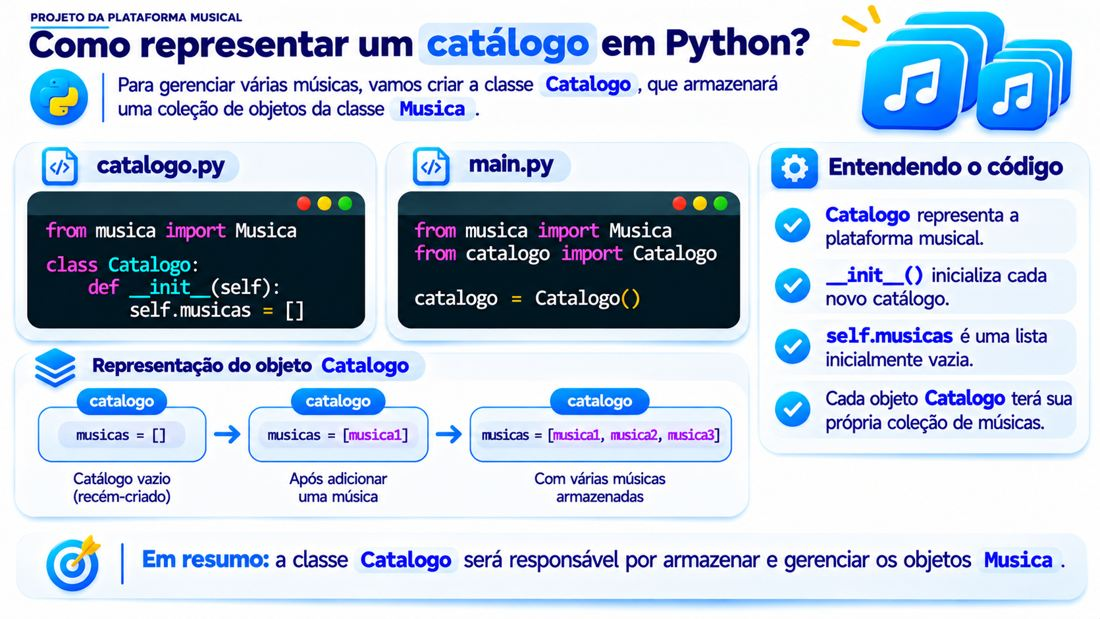

**Criação de `catalogo.py`**

Insira o código abaixo no novo arquivo. 

E insira também o `from musica import Musica` para que o catálogo reconheça os objetos da classe `Musica`.

---


```python
from musica import Musica

class Catalogo:
    def __init__(self):
            self.musicas = []
            self.musica_atual = None
            self.reproducoes = {}  # Contagem por objeto Musica
            self.favoritos = []
```
---
O parâmetro `self` identifica o catálogo que está sendo construído ou utilizado. Cada instância criada com `Catalogo()` recebe suas próprias listas, dicionário e referência de reprodução.

Cada atributo possui uma responsabilidade:
- `musicas`: lista com os objetos Musica cadastrados.
- `musica_atual`: referência à música em reprodução; None indica que nenhuma está tocando.
- `reproducoes`: dicionário que associa cada objeto Musica à sua quantidade de reproduções.
- `favoritos`: lista com os objetos Musica marcados como favoritos.

In [ ]:
from catalogo import Catalogo

**Primeira verificação:** Ao criar um objeto Catalogo, seus quatro atributos devem apresentar os valores iniciais definidos no construtor `__init__()`.

**Atividade:** instancie um catálogo, exiba os quatro atributos e verifique se os valores correspondem ao estado inicial esperado.

In [25]:
c1 =  Catalogo()

print("Músicas cadastradas:", c1.musicas)
print("Música em reprodução:", c1.musica_atual)
print("Contagem de reproduções:", c1.reproducoes)
print("Músicas favoritas:", c1.favoritos)


Músicas cadastradas: []
Música em reprodução: None
Contagem de reproduções: {}
Músicas favoritas: []



---
---
## Passo 6: Cadastrando músicas com `adicionar_musica()`

Agora que o catálogo possui uma lista para armazenar músicas, precisamos criar um método que permita adicionar novos objetos à coleção.

O método `adicionar_musica(self, musica)` deverá realizar três operações:

- **Validar o objeto:** verificar se o argumento recebido é uma instância da classe Musica, utilizando `isinstance()`. Caso contrário, lançar um TypeError.

- **Adicionar à coleção:** utilizar `.append()` para inserir o objeto na lista self.musicas.

- Inicializar as reproduções: registrar o objeto como chave no dicionário `self.reproducoes`, com contador inicial igual a zero.

Ao concluir essas operações, o método retorna uma mensagem, indicando que a música foi adicionada.

**slide 9**

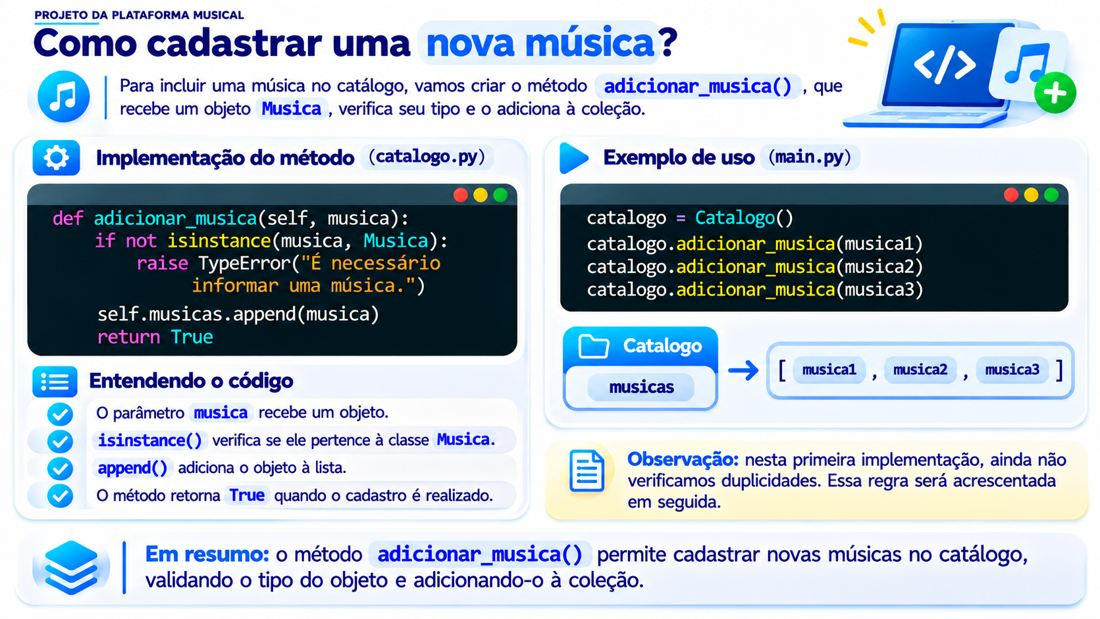

**Acrescente o método à classe `Catalogo`**

No arquivo **`catalogo.py`**, insira o método abaixo **dentro da classe `Catalogo`**, após o construtor. Não substitua os métodos existentes.

---

```python
    def adicionar_musica(self, musica):
        if not isinstance(musica, Musica):
            raise TypeError("É necessário informar um objeto Musica.")
        self.musicas.append(musica)
        self.reproducoes[musica] = 0
        print(f"A música {musica.nome} foi adicionada ao catálogo de músicas!")
```

In [3]:
from catalogo import Catalogo
from musica import Musica

m5 = Musica("Corazón Partío", "Alejandro Sanz", "Pop Latino", 343, 1997)
m6 = Musica ("Inner Light", "Elderbrook e Bob Moses", "Eletônica", 257, 2021)
m7 = Musica("Boate Azul", "Bruno & Marrone", "Sertanejo", 261, 1985)
m8 = Musica("Evidências", "Chitãozinho & Xororó", "Sertanejo", 293, 1990)
m9 = Musica("Corazón Partío", "Alejandro Sanz", "Pop Latino", 343, 1997)


musicas = [m5, m6, m7, m8, m9]


In [4]:
c2 = Catalogo()

for musica in musicas:
    c2.adicionar_musica(musica)
print(f"Total de músicas adicionadas: {len(c2.musicas)} musicas.")


A música Corazón Partío foi adiconada ao catálogo de músicas!
A música Inner Light foi adiconada ao catálogo de músicas!
A música Boate Azul foi adiconada ao catálogo de músicas!
A música Evidências foi adiconada ao catálogo de músicas!
A música Corazón Partío foi adiconada ao catálogo de músicas!
Total de músicas adicionadas: 5 musicas.


**Interpretação:** após cadastrar os objetos válidos, a lista deve conter as referências e o dicionário deve registrar o contador `0` para cada uma.